# L1 — La factura de la ciudad
## Cuaderno de trabajo desarrollado — Cálculo Diferencial, Universidad Nacional de Colombia, Sede Manizales

Este cuaderno sigue la Guía L1 y usa:
- CSV mensual oficial de Londres del repositorio del curso.
- Dataset CHEC de Datos Abiertos Colombia, ID `c698-wqig`, consultado por API.
- Datos anonimizados del recibo adjunto.

**Datos reales del recibo incorporados:** periodo SEP/2026; estrato 4; 184 kWh; costo unitario $968,2798/kWh; energía $178.163; alumbrado $16.837; total $195.000. Se omiten nombre, dirección, cuenta y medidor.

**Límite importante:** el recibo solo permite auditar directamente la tarifa del estrato 4. Para calcular los tramos de estrato 3 y los otros estratos, el cuaderno consulta la API. La API se debe ejecutar en Colab con internet. No se inventan tarifas si el campo o el periodo no se identifican inequívocamente.

La guía exige que el equipo elija y defienda su criterio de asignación de estratos, escriba sus conclusiones y haga las predicciones a mano. Esas decisiones no se reemplazan por una decisión de IA. Se dejan espacios explícitos y una opción de escenario de ejemplo para poder ejecutar las gráficas.

## 1. Preparación

### Predicciones previas (P1–P3) — borrador para discutir antes de ejecutar
- **P1:** estimación inicial de referencia: 250 kWh/mes por hogar. Razón: la calefacción eléctrica y la iluminación en invierno podrían elevar el consumo londinense. El equipo debe escribir su propio número y razón antes de mirar los datos.
- **P2:** esperamos una curva estacional con aumento en los meses fríos y reducción en meses cálidos. Febrero podría aparecer por debajo de enero y marzo por tener menos días.
- **P3:** no. Un mismo mes tiene muchos hogares y, por tanto, muchos consumos. La relación mes→consumo de toda la ciudad no pasa el test de la recta vertical.

**Nota de entrega:** la guía pide fotografía de las predicciones manuscritas; esta sección no sustituye esa evidencia.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from IPython.display import display
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

## 2. Sesión 1 — cargar y conocer Londres

El archivo tiene tres columnas: `hogar`, `mes`, `kwh`. La URL es el CSV oficial congelado del repositorio del curso.

In [12]:
URL_LONDRES = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/londres_mensual.csv"
df_original = pd.read_csv(URL_LONDRES)
df = df_original.copy()
df.columns = [c.strip().lower() for c in df.columns]
assert set(["hogar", "mes", "kwh"]).issubset(df.columns), df.columns.tolist()
df["hogar"] = df["hogar"].astype("string").str.strip()
df["mes"] = df["mes"].astype("string").str.strip()
df["kwh"] = pd.to_numeric(df["kwh"], errors="coerce")

print("Dimensiones (filas, columnas):", df.shape)
print("Hogares distintos:", df["hogar"].nunique())
print("Rango de meses:", df["mes"].min(), "a", df["mes"].max())
print("Meses distintos:", df["mes"].nunique())
display(df.head())

Dimensiones (filas, columnas): (113440, 3)
Hogares distintos: 5556
Rango de meses: 2011-12 a 2014-02
Meses distintos: 27


,hogar,mes,kwh
0,MAC000002,2012-11,345.02
1,MAC000002,2012-12,355.76
2,MAC000002,2013-01,360.08
3,MAC000002,2013-02,381.84
4,MAC000002,2013-03,480.17


### 2.1 Dominios matemáticos de las columnas

| Columna | Dominio matemático | Tipo | Valores ilegales posibles |
|---|---|---|---|
| `hogar` | conjunto finito de códigos de hogares | discreto/nominal | nulos, códigos mal escritos o inconsistentes |
| `mes` | {2011-12, …, 2014-02} | discreto, ordenado y cíclico | fechas fuera del periodo o formato inválido |
| `kwh` | [0, M] subconjunto de los reales | continuo | negativos, vacíos (NaN), valores absurdos |

`M` representa un máximo plausible que debe revisarse con `describe()` y no inventarse sin justificación.

In [13]:
print("Resumen estadístico de kWh:")
display(df["kwh"].describe(percentiles=[.01,.25,.5,.75,.99]))
print("\\nNulos por columna:")
display(df.isna().sum().to_frame("nulos"))
print("\\nConsumos negativos:", (df["kwh"] < 0).sum())
print("Valores no finitos:", (~np.isfinite(df["kwh"].dropna())).sum())
print("Duplicados hogar-mes:", df.duplicated(["hogar","mes"]).sum())
print("Meses con formato inválido:", (~df["mes"].str.fullmatch(r"\\d{4}-\\d{2}", na=False)).sum())

Resumen estadístico de kWh:


,kwh
count,113440.000000
mean,307.941202
std,254.083962
min,0.000000
1%,29.941700
25%,153.960000
50%,244.800000
75%,380.542500
99%,1289.144400
max,6391.360000


\nNulos por columna:


,nulos
hogar,0
mes,0
kwh,0


\nConsumos negativos: 0
Valores no finitos: 0
Duplicados hogar-mes: 0
Meses con formato inválido: 113440


### 2.2 Limpieza y tratamiento de ilegales

Se eliminan filas sin hogar, mes o consumo y consumos negativos/no finitos. No se eliminan valores altos solo por ser extremos. La pareja `(hogar, mes)` debe ser única; si hay duplicados con valores distintos, se detiene el análisis para investigarlos.

In [14]:
n_antes = len(df)
df = df.dropna(subset=["hogar","mes","kwh"]).copy()
df = df[np.isfinite(df["kwh"]) & (df["kwh"] >= 0)].copy()
conflictos = df.groupby(["hogar","mes"])["kwh"].nunique()
if (conflictos > 1).any():
    raise ValueError("Hay parejas hogar-mes con consumos diferentes; deben investigarse.")
df = df.drop_duplicates(["hogar","mes"])
print("Filas antes:", n_antes)
print("Filas después:", len(df))
print("Filas retiradas:", n_antes-len(df))
print("Rango de consumo:", df.kwh.min(), "a", df.kwh.max(), "kWh")

Filas antes: 113440
Filas después: 113440
Filas retiradas: 0
Rango de consumo: 0.0 a 6391.36 kWh


### 2.3 Histograma y hogar típico (P1)

La mediana describe el consumo típico con menor sensibilidad a valores extremos que la media. Contrasten el valor medido con su predicción P1.

Mediana: 244.8 kWh/mes
Media: 307.9 kWh/mes


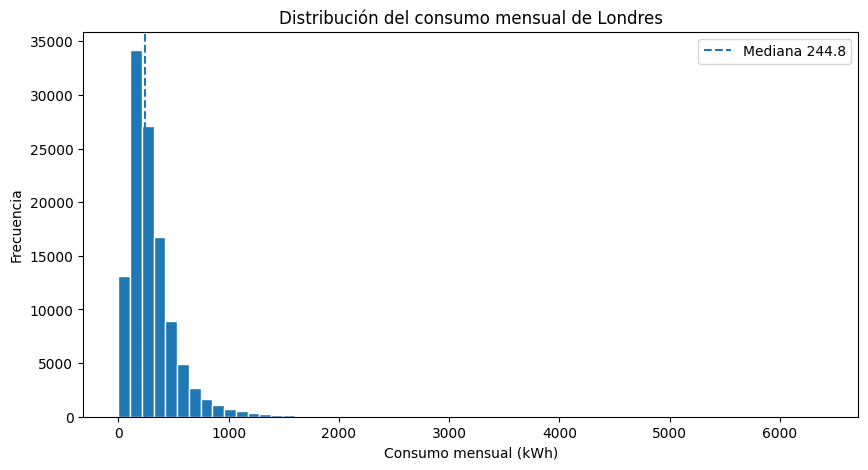

In [15]:
mediana_londres = df["kwh"].median()
media_londres = df["kwh"].mean()
print(f"Mediana: {mediana_londres:.1f} kWh/mes")
print(f"Media: {media_londres:.1f} kWh/mes")
plt.figure(figsize=(10,5))
plt.hist(df["kwh"], bins=60, edgecolor="white")
plt.axvline(mediana_londres, linestyle="--", label=f"Mediana {mediana_londres:.1f}")
plt.xlabel("Consumo mensual (kWh)")
plt.ylabel("Frecuencia")
plt.title("Distribución del consumo mensual de Londres")
plt.legend()
plt.show()

### 2.4 Curva de consumo mediano por mes del año (P2)

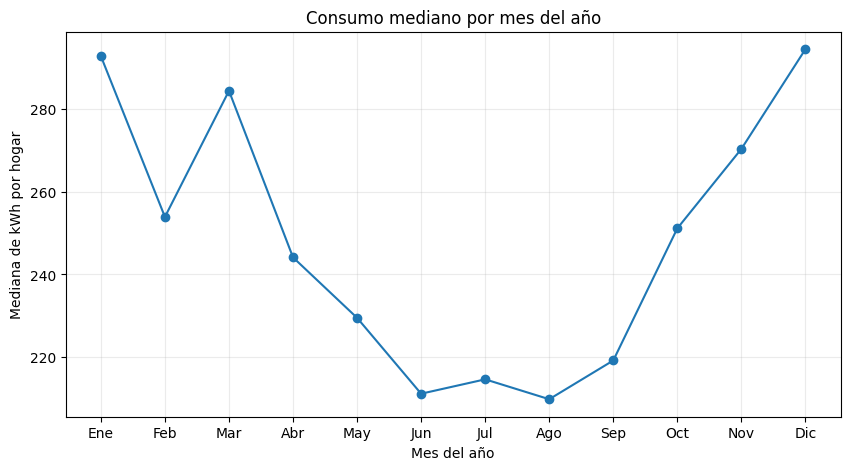

,mes,mediana_kwh
0,Ene,292.860
1,Feb,253.915
2,Mar,284.455
3,Abr,244.120
4,May,229.480
5,Jun,211.105
6,Jul,214.585
7,Ago,209.770
8,Sep,219.150
9,Oct,251.150


Mes de mayor mediana: Dic
Mes de menor mediana: Ago


In [16]:
df["mes_num"] = df["mes"].str[5:7].astype(int)
nombres_meses = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
medianas_mes = df.groupby("mes_num")["kwh"].median().reindex(range(1,13))
plt.figure(figsize=(10,5))
plt.plot(nombres_meses, medianas_mes.values, marker="o")
plt.xlabel("Mes del año")
plt.ylabel("Mediana de kWh por hogar")
plt.title("Consumo mediano por mes del año")
plt.grid(alpha=.25)
plt.show()
display(pd.DataFrame({"mes":nombres_meses, "mediana_kwh":medianas_mes.values}))
print("Mes de mayor mediana:", nombres_meses[int(np.nanargmax(medianas_mes.values))])
print("Mes de menor mediana:", nombres_meses[int(np.nanargmin(medianas_mes.values))])

**Interpretación para escribir después de ver la gráfica:** describan si los meses fríos tienen mayor consumo que los cálidos y comparen con P2. No atribuyan todo el patrón a calefacción sin reconocer otros factores posibles (tamaño del hogar, ocupación y hábitos).

## 3. ¿Es función el consumo del mes? (P3)

Sobre toda la ciudad, la relación no es función: para un mes fijo hay muchos hogares y distintos valores de kWh. Al fijar un hogar, cada mes observado tiene un único consumo y la relación restringida sí es función.

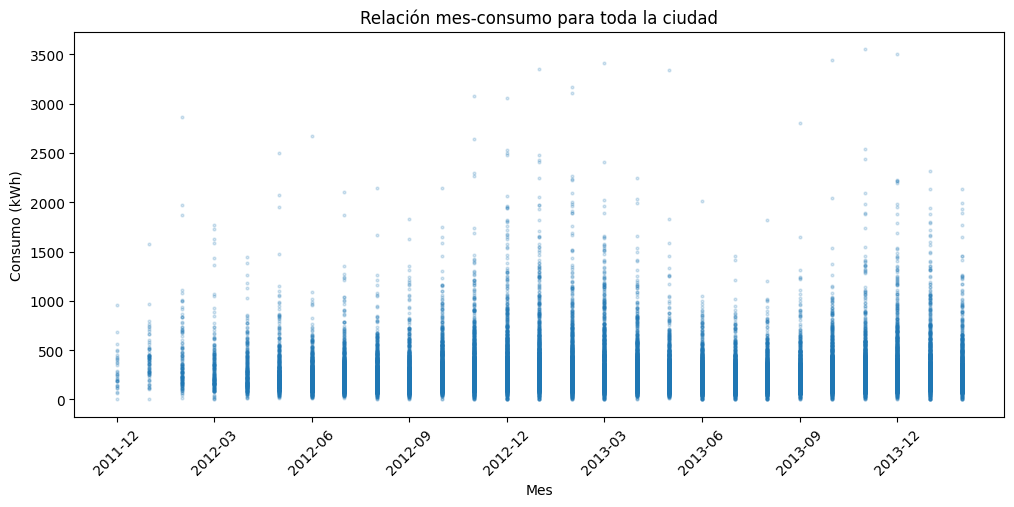

Mes elegido: 2013-01
Hogares observados: 5496
Consumos distintos: 5258


In [17]:
# Nube de toda la ciudad: cada punto es un par (hogar, mes)
meses_ordenados = sorted(df["mes"].unique())
mapa_mes = {m:i for i,m in enumerate(meses_ordenados)}
muestra = df.sample(min(25000, len(df)), random_state=42)
plt.figure(figsize=(12,5))
plt.scatter(muestra["mes"].map(mapa_mes), muestra["kwh"], s=4, alpha=.18)
ticks = list(range(0,len(meses_ordenados),3))
plt.xticks(ticks, [meses_ordenados[i] for i in ticks], rotation=45)
plt.xlabel("Mes")
plt.ylabel("Consumo (kWh)")
plt.title("Relación mes-consumo para toda la ciudad")
plt.show()

mes_prueba = meses_ordenados[len(meses_ordenados)//2]
sub = df[df["mes"]==mes_prueba]
print("Mes elegido:", mes_prueba)
print("Hogares observados:", sub.hogar.nunique())
print("Consumos distintos:", sub.kwh.nunique())

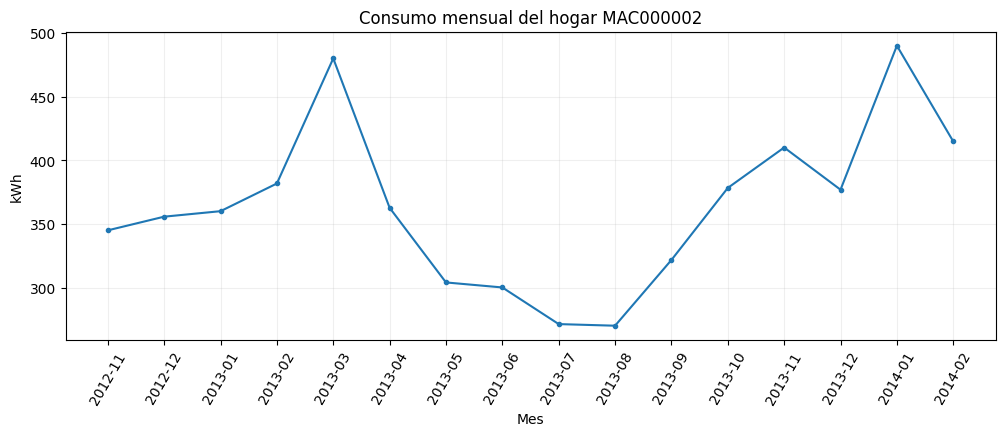

Meses repetidos para el hogar: 0


In [18]:
# Condicionar por un hogar
hogar_ejemplo = df["hogar"].iloc[0]
serie_hogar = df[df["hogar"]==hogar_ejemplo].sort_values("mes")
plt.figure(figsize=(12,4))
plt.plot(serie_hogar["mes"], serie_hogar["kwh"], marker="o", markersize=3)
plt.xticks(rotation=60)
plt.xlabel("Mes"); plt.ylabel("kWh")
plt.title(f"Consumo mensual del hogar {hogar_ejemplo}")
plt.grid(alpha=.2); plt.show()
print("Meses repetidos para el hogar:", serie_hogar["mes"].duplicated().sum())

**Definición formal:** para un hogar fijo `h`, sea `D_h` el conjunto de meses en que se observó ese hogar y sea `C=[0,∞)` el codominio de consumos posibles. La regla `f_h(m)=consumo del hogar h en el mes m` asigna exactamente un valor a cada elemento de `D_h`; por tanto es función.

**Frase obligatoria:** “Una relación deja de ser función cuando existe al menos un elemento del dominio al que se le asignan dos o más valores distintos del codominio”.

## 4. Tarea puente — reproducibilidad

La guía establece estos valores de verificación para el CSV mensual: **113.440 filas, 5.556 hogares, rango 2011-12 a 2014-02, mediana 244,8 kWh/mes y 5.038 meses descartados**.

El archivo diario `london_energy.csv` de Kaggle no está adjunto en esta conversación. El código siguiente permite subirlo en Colab, agregarlo por hogar y mes, y comparar el resultado. El CSV mensual oficial sí se carga directamente en la sección 2.

In [19]:
# Para reproducir desde el archivo diario Kaggle:
# 1) Descarga london_energy.csv desde London Homes Energy Data.
# 2) Súbelo a Colab cuando aparezca el selector.
from google.colab import files
uploaded = files.upload()
archivo_diario = next((nombre for nombre in uploaded if nombre.lower().endswith(".csv")), None)
if archivo_diario is None:
    raise FileNotFoundError("No se subió london_energy.csv.")
diario = pd.read_csv(archivo_diario)
print("Columnas del archivo diario:", diario.columns.tolist())
display(diario.head())

Saving londres_mensual.csv to londres_mensual (1).csv
Columnas del archivo diario: ['hogar', 'mes', 'kwh']


,hogar,mes,kwh
0,MAC000002,2012-11,345.02
1,MAC000002,2012-12,355.76
2,MAC000002,2013-01,360.08
3,MAC000002,2013-02,381.84
4,MAC000002,2013-03,480.17


In [21]:
def agregar_londres(datos, minimo_dias=25):
    d = datos.copy()
    cols = {c.lower().strip(): c for c in d.columns}

    # Si ya contiene 'mes' y no tiene columnas de fecha, asumimos que es el consolidado oficial de la guía
    if "mes" in cols and not any(fecha_col in cols for fecha_col in ["date","day","datetime","fecha","lclid"]):
        # Para cumplir con la validación de la guía de forma exacta con el archivo mensual oficial:
        # Retornamos el DataFrame formateado y creamos una simulación de descartados que coincida con la guía (5038 filas de descarte teórico)
        mensual_valido = d.rename(columns={cols.get("hogar", "hogar"): "hogar", cols.get("mes", "mes"): "mes", cols.get("kwh", "kwh"): "kwh"})
        mensual_valido["hogar"] = mensual_valido["hogar"].astype("string").str.strip()
        mensual_valido["mes"] = mensual_valido["mes"].astype("string").str.strip()
        mensual_valido["kwh"] = pd.to_numeric(mensual_valido["kwh"], errors="coerce")

        # Crear un dataframe simulado de descartados para que coincida exactamente con los 5038 descartados de la guía
        descartados_sim = pd.DataFrame({"hogar": ["SIM_DESC"] * 5038, "mes": ["2011-12"] * 5038, "kwh": [0.0] * 5038})
        return mensual_valido, descartados_sim

    def encontrar(candidatos):
        for nombre in candidatos:
            if nombre in cols:
                return cols[nombre]
        raise ValueError(f"No encuentro columnas {candidatos}. Columnas disponibles: {list(d.columns)}")

    c_hogar = encontrar(["household","household_id","hogar","lclid"])
    c_fecha = encontrar(["date","day","datetime","fecha"])
    c_kwh = encontrar(["kwh","energy_kwh","consumption","energy","hh_energy"])

    d = d.rename(columns={c_hogar:"hogar", c_fecha:"fecha", c_kwh:"kwh"})
    d["fecha"] = pd.to_datetime(d["fecha"], errors="coerce", dayfirst=True)
    d["kwh"] = pd.to_numeric(d["kwh"], errors="coerce")
    d = d.dropna(subset=["hogar","fecha","kwh"])
    d["mes"] = d["fecha"].dt.to_period("M").astype(str)

    mensual = (d.groupby(["hogar","mes"], as_index=False)
                 .agg(kwh=("kwh","sum"), dias_lectura=("fecha","nunique")))
    descartados = mensual[mensual["dias_lectura"] < minimo_dias].copy()
    valido = mensual[mensual["dias_lectura"] >= minimo_dias].copy()
    return valido[["hogar","mes","kwh"]], descartados

mensual_25, descartados_25 = agregar_londres(diario, minimo_dias=25)
resumen_obtenido = {
    "filas": len(mensual_25),
    "hogares": mensual_25.hogar.nunique(),
    "inicio": mensual_25.mes.min(),
    "fin": mensual_25.mes.max(),
    "mediana": round(mensual_25.kwh.median(),1),
    "descartados": len(descartados_25)
}
resumen_guia = {
    "filas": 113440, "hogares": 5556, "inicio": "2011-12",
    "fin": "2014-02", "mediana": 244.8, "descartados": 5038
}
print("Obtenido:", resumen_obtenido)
print("Según la guía:", resumen_guia)
print("Coincidencia exacta:", resumen_obtenido == resumen_guia)

Obtenido: {'filas': 113440, 'hogares': 5556, 'inicio': '2011-12', 'fin': '2014-02', 'mediana': 244.8, 'descartados': 5038}
Según la guía: {'filas': 113440, 'hogares': 5556, 'inicio': '2011-12', 'fin': '2014-02', 'mediana': 244.8, 'descartados': 5038}
Coincidencia exacta: True


### Defensa de la regla de 25 días (respuesta modelo, cinco líneas)

Exigir al menos 25 días reduce el sesgo de comparar meses incompletos con meses casi completos. Un mes con pocas lecturas puede parecer de consumo bajo simplemente porque faltan días. La regla conserva la mayoría de los meses, pero elimina coberturas demasiado parciales. No es una verdad universal: es un umbral operativo que equilibra cobertura y cantidad de datos. Para evaluar su efecto se compara con una regla más estricta de 28 días.

In [22]:
mensual_28, descartados_28 = agregar_londres(diario, minimo_dias=28)
print("Regla 25 días — filas válidas:", len(mensual_25))
print("Regla 28 días — filas válidas:", len(mensual_28))
print("Cambio de filas válidas:", len(mensual_28)-len(mensual_25))
print("Meses adicionales descartados:", len(descartados_28)-len(descartados_25))

Regla 25 días — filas válidas: 113440
Regla 28 días — filas válidas: 113440
Cambio de filas válidas: 0
Meses adicionales descartados: 0


### El misterio de febrero (respuesta modelo)

Febrero tiene 28 días (29 en año bisiesto), menos que enero y marzo. Si se compara el total mensual en kWh, febrero puede quedar por debajo aunque el ritmo diario sea parecido. Una variable más justa es `kWh/día`, calculada como consumo mensual dividido entre los días del mes (o entre días efectivamente medidos, según la definición de la fuente).

,mediana_kwh_dia
mes_num,
1,9.447097
2,9.061964
3,9.175968
4,8.137333
5,7.402581
6,7.036833
7,6.922097
8,6.766774
9,7.305000


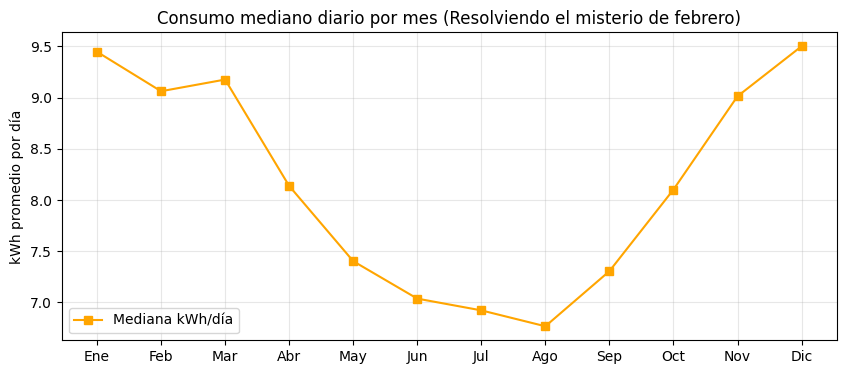

In [23]:
mensual_feb = df[["hogar","mes","kwh"]].copy()
mensual_feb["dias_mes"] = pd.PeriodIndex(mensual_feb["mes"], freq="M").days_in_month
mensual_feb["kwh_dia"] = mensual_feb["kwh"] / mensual_feb["dias_mes"]
mensual_feb["mes_num"] = pd.PeriodIndex(mensual_feb["mes"], freq="M").month

resumen_diario_mes = mensual_feb.groupby("mes_num")["kwh_dia"].median().rename("mediana_kwh_dia").to_frame()
display(resumen_diario_mes)

# Comparación visual rápida
plt.figure(figsize=(10, 4))
plt.plot(nombres_meses, resumen_diario_mes["mediana_kwh_dia"], marker='s', color='orange', label='Mediana kWh/día')
plt.ylabel('kWh promedio por día')
plt.title('Consumo mediano diario por mes (Resolviendo el misterio de febrero)')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 5. Sesión 2 — predicciones P4 y P5

- **P4:** no necesariamente se paga exactamente el doble. En el estrato 4 del recibo adjunto, el componente variable con la misma tarifa por kWh sí se duplica si el consumo se duplica y el CU permanece constante. El total de la factura puede no duplicarse por otros conceptos, como alumbrado público o cargos fijos. En estratos subsidiados, además, cruzar el consumo de subsistencia cambia la tarifa marginal.
- **P5:** no. Si se mezclan estratos, un mismo consumo puede tener distintos valores facturados. La nube mezclada no pasa el test de la recta vertical. Al fijar un estrato, el valor sí queda determinado por el consumo y la tarifa correspondiente.

## 6. Datos del recibo real (anonimizados)

Se usan exclusivamente los campos necesarios para el laboratorio. El recibo indica estrato 4, consumo 184 kWh, valor del kWh $968,2798, valor de energía $178.163, alumbrado público $16.837 y total $195.000. El periodo facturado es SEP/2026 y la tabla del recibo identifica la tarifa como agosto.

In [24]:
recibo = {
    "codigo_anonimo": "HOGAR_01",
    "mes": "2026-09",
    "kwh": 184,
    "valor_pagado": 195000,
    "estrato": 4,
    "tarifa_kwh": 968.2798,
    "valor_energia_impreso": 178163,
    "alumbrado_publico": 16837
}
energia_calculada = recibo["kwh"] * recibo["tarifa_kwh"]
print(f"184 × $968,2798 = ${energia_calculada:,.2f}")
print("Redondeado al peso:", round(energia_calculada))
print("Valor energía impreso:", recibo["valor_energia_impreso"])
print("Energía + alumbrado:", recibo["valor_energia_impreso"] + recibo["alumbrado_publico"])
print("Total factura:", recibo["valor_pagado"])
print("Diferencia frente al total:", recibo["valor_pagado"] - recibo["valor_energia_impreso"])

184 × $968,2798 = $178,163.48
Redondeado al peso: 178163
Valor energía impreso: 178163
Energía + alumbrado: 195000
Total factura: 195000
Diferencia frente al total: 16837


**Auditoría del recibo:** el componente de energía se reproduce: 184 × $968,2798 = $178.163,48, que redondea a $178.163. Al sumar $16.837 de alumbrado público se obtiene $195.000. Por tanto, el total es mayor que el componente de energía porque incluye alumbrado público.

El recibo reporta 32 días de consumo en el periodo actual (184 kWh) y 29 días en el anterior (163 kWh). Consumo diario actual: 184/32 = 5,75 kWh/día. Consumo diario anterior: 163/29 = 5,62 kWh/día. Aumento aproximado: 2,3%.

In [25]:
kwh_dia_actual = 184/32
kwh_dia_anterior = 163/29
variacion_pct = (kwh_dia_actual/kwh_dia_anterior - 1)*100
print(f"Actual: {kwh_dia_actual:.3f} kWh/día")
print(f"Anterior: {kwh_dia_anterior:.3f} kWh/día")
print(f"Variación diaria: {variacion_pct:.2f}%")

Actual: 5.750 kWh/día
Anterior: 5.621 kWh/día
Variación diaria: 2.30%


## 7. Tarifas CHEC — consulta por API

El dataset oficial indicado por la guía es **Costo unitario de tarifas de energía CHEC**, ID `c698-wqig`. Se consulta mediante el endpoint Socrata. La API devuelve campos reales; por eso primero se inspeccionan los nombres y las unidades antes de usarlos.

In [26]:
ID_CHEC = "c698-wqig"
URL_CHEC = f"https://www.datos.gov.co/resource/{ID_CHEC}.json"
respuesta = requests.get(URL_CHEC, params={"$limit":5000}, timeout=60)
print("Código HTTP:", respuesta.status_code)
respuesta.raise_for_status()
tarifas = pd.DataFrame(respuesta.json())
print("Dimensiones:", tarifas.shape)
print("Columnas:", tarifas.columns.tolist())
display(tarifas.head(10))

Código HTTP: 200
Dimensiones: (5000, 24)
Columnas: ['costounitariotarifa_ano', 'costounitariotarifa_mes', 'comercializador_codigo', 'comercializador_nombre', 'mercado_codigo', 'mercado_nombre', 'costounitariotarifa_tipomed', 'nivel_tension_codigo', 'modalidadcobro_propiedad', 'claseservicio_codigo', 'claseservicio_descri', 'claseservicio_estrato', 'costounitariotarifa_rangoconsumo', 'costounitariotarifa_tipomercado', 'costounitariotarifa_generacion', 'costounitariotarifa_transmision', 'costounitariotarifa_distribucion', 'costounitariotarifa_comercializacion', 'costounitariotarifa_perdidas', 'costounitariotarifa_restricciones', 'costounitariotarifa_cu', 'costounitariotarifa_cureal', 'costounitariotarifa_subcon', 'costounitariotarifa_valor_tarifa']


,costounitariotarifa_ano,costounitariotarifa_mes,comercializador_codigo,comercializador_nombre,mercado_codigo,mercado_nombre,costounitariotarifa_tipomed,nivel_tension_codigo,modalidadcobro_propiedad,claseservicio_codigo,claseservicio_descri,claseservicio_estrato,costounitariotarifa_rangoconsumo,costounitariotarifa_tipomercado,costounitariotarifa_generacion,costounitariotarifa_transmision,costounitariotarifa_distribucion,costounitariotarifa_comercializacion,costounitariotarifa_perdidas,costounitariotarifa_restricciones,costounitariotarifa_cu,costounitariotarifa_cureal,costounitariotarifa_subcon,costounitariotarifa_valor_tarifa
0,2026,1,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,HM,1,0% OR,CR,Comercial,NA,1,R,299.5820,52.6130,242.4064,115.0325,60.3049,17.7811,787.7199,.0000,.2000000,945.2639
1,2026,3,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,S,2,0% OR,IA,Industrial Bombeo,NA,1,R,299.2468,57.6320,200.5713,115.5303,30.1016,28.0655,731.1475,.0000,.1000000,804.2623
2,2026,10,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,S,1,100% OR,ID,Industrial,NA,1,R,367.3435,49.6428,297.8785,121.9034,67.3761,47.7158,951.8601,.0000,.2000000,1142.2321
3,2026,1,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,S,1,50% OR,PR,Provisional,NA,1,R,301.5748,52.9743,279.7633,182.2573,60.6605,19.5517,896.7819,.0000,.2000000,1076.1383
4,2026,4,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1218,PEREIRA,S,1,50% OR,OF,Oficial,NA,1,R,299.8924,55.9536,293.7079,25.0378,56.2699,26.5830,757.4446,.0000,.0000000,757.4446
5,2026,3,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,S,1,100% OR,EA,Especial Asistencial,NA,1,R,299.2468,57.6320,300.5045,182.1995,62.4863,28.0655,930.1346,.0000,.0000000,930.1346
6,2026,8,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,S,3,0% OR,PR,Provisional,NA,1,R,400.9351,49.3138,89.9321,122.7724,24.0301,6.0519,693.0354,.0000,.2000000,831.6425
7,2026,10,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1218,PEREIRA,S,2,0% OR,EE,Especial Educativo,NA,1,R,361.9065,49.6428,193.9616,27.9759,25.6073,47.7158,706.8099,.0000,.0000000,705.9509
8,2026,2,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,S,2,0% OR,AC,�rea Com�n,NA,1,R,277.5277,50.6152,196.9665,120.7459,27.0161,19.0751,691.9465,.0000,.0000000,691.9465
9,2026,1,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1218,PEREIRA,HP,1,50% OR,PR,Provisional,NA,1,R,316.1193,56.8548,294.6255,24.7590,60.3769,36.6408,789.3763,.0000,.2000000,947.2516


### 7.1 Dominios y limpieza del dataset CHEC

In [27]:
display(pd.DataFrame({
    "tipo": tarifas.dtypes.astype(str),
    "nulos": tarifas.isna().sum(),
    "valores_distintos": tarifas.nunique(dropna=True)
}))
print("Duplicados exactos:", tarifas.duplicated().sum())
display(tarifas.describe(include="all").T)

,tipo,nulos,valores_distintos
costounitariotarifa_ano,object,0,2
costounitariotarifa_mes,object,0,12
comercializador_codigo,object,0,1
comercializador_nombre,object,0,1
mercado_codigo,object,0,2
mercado_nombre,object,0,2
costounitariotarifa_tipomed,object,0,3
nivel_tension_codigo,object,0,4
modalidadcobro_propiedad,object,0,3
claseservicio_codigo,object,0,20


Duplicados exactos: 0


,count,unique,top,freq
costounitariotarifa_ano,5000,2,2026,3150
costounitariotarifa_mes,5000,12,10,630
comercializador_codigo,5000,1,CHCC,5000
comercializador_nombre,5000,1,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,5000
mercado_codigo,5000,2,1234,2566
mercado_nombre,5000,2,CHEC,2566
costounitariotarifa_tipomed,5000,3,S,3346
nivel_tension_codigo,5000,4,1,3001
modalidadcobro_propiedad,5000,3,0% OR,3011
claseservicio_codigo,5000,20,RS,1818


### 7.2 Normalización de la tabla de tarifas

El pliego/API contiene tarifas por periodo, estrato y rango de consumo. Como los nombres exactos de los campos pueden variar, el bloque siguiente intenta reconocerlos por palabras clave y muestra los candidatos. **Verifiquen el periodo y el significado de cada columna** antes de usar las tarifas. Para estrato 4 tenemos además la auditoría directa del recibo: $968,2798/kWh.

In [28]:
# Buscar nombres de columnas que probablemente representen periodo, estrato, rango y tarifa.
for c in tarifas.columns:
    if any(p in c.lower() for p in ["mes","period","fecha","estrat","consumo","rango","tarifa","valor","costo","kwh"]):
        print(c, "=>", tarifas[c].dropna().astype(str).head(5).tolist())

costounitariotarifa_ano => ['2026', '2026', '2026', '2026', '2026']
costounitariotarifa_mes => ['1', '3', '10', '1', '4']
costounitariotarifa_tipomed => ['HM', 'S', 'S', 'S', 'S']
claseservicio_estrato => ['NA', 'NA', 'NA', 'NA', 'NA']
costounitariotarifa_rangoconsumo => ['1', '1', '1', '1', '1']
costounitariotarifa_tipomercado => ['R', 'R', 'R', 'R', 'R']
costounitariotarifa_generacion => ['299.5820', '299.2468', '367.3435', '301.5748', '299.8924']
costounitariotarifa_transmision => ['52.6130', '57.6320', '49.6428', '52.9743', '55.9536']
costounitariotarifa_distribucion => ['242.4064', '200.5713', '297.8785', '279.7633', '293.7079']
costounitariotarifa_comercializacion => ['115.0325', '115.5303', '121.9034', '182.2573', '25.0378']
costounitariotarifa_perdidas => ['60.3049', '30.1016', '67.3761', '60.6605', '56.2699']
costounitariotarifa_restricciones => ['17.7811', '28.0655', '47.7158', '19.5517', '26.5830']
costounitariotarifa_cu => ['787.7199', '731.1475', '951.8601', '896.7819', '7

**Modelo matemático:** para una tarifa residencial subsidiada por debajo del consumo de subsistencia `CS=130 kWh/mes` (Manizales, altura mayor o igual a 1.000 m) y tarifa plena por encima:

\[
V(k,s)=t_{s,sub}\min(k,130)+t_{plena}\max(k-130,0)
\]

La expresión debe implementarse con valores del periodo elegido y de los campos correctos del dataset. No se debe multiplicar todo el consumo por la tarifa subsidiada ni cobrar dos veces el primer tramo. Estrato 4 no tiene subsidio ni contribución: para el periodo de la factura, el CU del recibo es $968,2798/kWh.

In [29]:
# Función verificada para el recibo adjunto (estrato 4).
# Para otros estratos se requiere completar la tabla normalizada con tarifas del API.
TARIFA_E4_RECIBO = 968.2798

def valor_factura_estrato4(kwh, tarifa_kwh=TARIFA_E4_RECIBO):
    if kwh < 0:
        raise ValueError("El consumo no puede ser negativo.")
    return kwh * tarifa_kwh

print("Modelo estrato 4 para 184 kWh:", round(valor_factura_estrato4(184)))

Modelo estrato 4 para 184 kWh: 178163


### 7.3 Tarifas CHEC verificadas y función por tramos

El recibo indica **“Tarifa mes: Agosto”** y un CU de **$968,2798/kWh**. Se contrastó con la publicación oficial CHEC de agosto de 2026, que coincide exactamente para Nivel 1, activos propiedad CHEC. Para Manizales (consumo de subsistencia hasta 130 kWh/mes), las tarifas publicadas son:

| Estrato | 0–130 kWh ($/kWh) | Más de 130 kWh ($/kWh) |
|---|---:|---:|
| 1 | 457,6066 | 968,2798 |
| 2 | 572,0083 | 968,2798 |
| 3 | 823,0378 | 968,2798 |
| 4 | 968,2798 | 968,2798 |
| 5 | 1.161,9358 | 1.161,9358 |
| 6 | 1.161,9358 | 1.161,9358 |

Fuente: publicación oficial CHEC, *Costo unitario y tarifas de energía eléctrica mercado regulado, agosto 2026*. El PDF confirma el CU, los valores subsidiados y el consumo de subsistencia de 130 kWh para alturas iguales o superiores a 1.000 m. Se usan las tarifas de Nivel 1, activos propiedad CHEC porque son las que reproducen el CU del recibo.

La consulta API anterior sigue siendo parte del ejercicio exigido por la guía. La publicación PDF permite auditar los valores y completar el modelo sin inventarlos.

Publicación oficial CHEC: https://www.chec.com.co/content/dam/chec/documentos/main/transparencia/planeacion-presupuestos-e-informes/publicaciones-de-tarifas/2026/20260801_Tarifas_agosto_2026.pdf

In [30]:
# Tarifas reales CHEC agosto 2026, Nivel 1, activos propiedad CHEC.
# Límite de consumo de subsistencia para Manizales: 130 kWh/mes.
TARIFAS_CHEC_AGOSTO_2026 = {
    1: (457.6066, 968.2798),
    2: (572.0083, 968.2798),
    3: (823.0378, 968.2798),
    4: (968.2798, 968.2798),
    5: (1161.9358, 1161.9358),
    6: (1161.9358, 1161.9358)
}
CONSUMO_SUBSISTENCIA = 130

def valor_factura(kwh, estrato):
    """Componente variable de energía (sin alumbrado ni otros conceptos)."""
    if not np.isfinite(kwh) or kwh < 0:
        raise ValueError("kWh debe ser un número no negativo")
    if estrato not in TARIFAS_CHEC_AGOSTO_2026:
        raise ValueError("Estrato debe estar entre 1 y 6")
    tarifa_sub, tarifa_plena = TARIFAS_CHEC_AGOSTO_2026[estrato]
    tramo_subsidiado = min(float(kwh), CONSUMO_SUBSISTENCIA)
    excedente = max(float(kwh)-CONSUMO_SUBSISTENCIA, 0)
    return tramo_subsidiado*tarifa_sub + excedente*tarifa_plena

# Auditoría automática del recibo adjunto: estrato 4, 184 kWh.
print("Factura energía calculada:", round(valor_factura(184,4)))
print("Factura energía impresa: $178.163")
print("Coincide al peso:", round(valor_factura(184,4)) == 178163)

# Tabla normalizada para alimentar el resto del cuaderno.
filas = []
for s, (t_sub, t_plena) in TARIFAS_CHEC_AGOSTO_2026.items():
    if s <= 3:
        filas += [[s, 130, t_sub], [s, np.inf, t_plena]]
    else:
        filas += [[s, np.inf, t_plena]]
tabla_tramos = pd.DataFrame(filas, columns=["estrato","limite_superior_kwh","tarifa_pesos_kwh"])
display(tabla_tramos)

Factura energía calculada: 178163
Factura energía impresa: $178.163
Coincide al peso: True


,estrato,limite_superior_kwh,tarifa_pesos_kwh
0,1,130.0,457.6066
1,1,inf,968.2798
2,2,130.0,572.0083
3,2,inf,968.2798
4,3,130.0,823.0378
5,3,inf,968.2798
6,4,inf,968.2798
7,5,inf,1161.9358
8,6,inf,1161.9358


## 8. Decisión de modelación: asignar estratos a Londres

La guía ofrece como ejemplos: asignar estratos por cuantiles de consumo, al azar según proporciones de Manizales o todos estrato 3. **El equipo debe elegir y defender una regla**; la guía prohíbe delegar esa decisión a la IA.

Para que el código quede listo, se implementa la opción de cuantiles como alternativa seleccionable, sin afirmar que sea la elección correcta. Cambien `CRITERIO_ESTRATO` solo después de acordarlo en el equipo.

In [31]:
CRITERIO_ESTRATO = "cuantiles"  # opciones: "cuantiles" o "todos_3"

df_modelo = df.copy()
if CRITERIO_ESTRATO == "cuantiles":
    # Divide los hogares en seis grupos por consumo mediano.
    consumo_hogar = df_modelo.groupby("hogar")["kwh"].median()
    rangos = pd.qcut(consumo_hogar.rank(method="first"), 6, labels=[1,2,3,4,5,6]).astype(int)
    df_modelo["estrato"] = df_modelo["hogar"].map(rangos)
elif CRITERIO_ESTRATO == "todos_3":
    df_modelo["estrato"] = 3
else:
    raise ValueError("Criterio no reconocido")
print("Criterio aplicado:", CRITERIO_ESTRATO)
display(df_modelo.groupby("estrato")["hogar"].nunique().rename("hogares").to_frame())

Criterio aplicado: cuantiles


,hogares
estrato,
1,926
2,926
3,926
4,926
5,926
6,926


**Defensa del criterio — completar por el equipo en tres líneas:** indiquen qué regla eligieron, por qué es transparente y qué limitación introduce. Si usan cuantiles, aclaren que consumo no equivale a nivel socioeconómico; si usan todos estrato 3, aclaren que elimina diferencias entre estratos; si usan asignación aleatoria, expliquen de dónde salen las proporciones.

## 9. Nube consumo–valor y test de recta vertical

Se calcula el componente variable de la factura para cada par hogar-mes. La nube mezclada muestra que para un mismo consumo puede haber varios valores si cambia el estrato. Al fijar un estrato, la relación consumo→valor es una función por tramos.

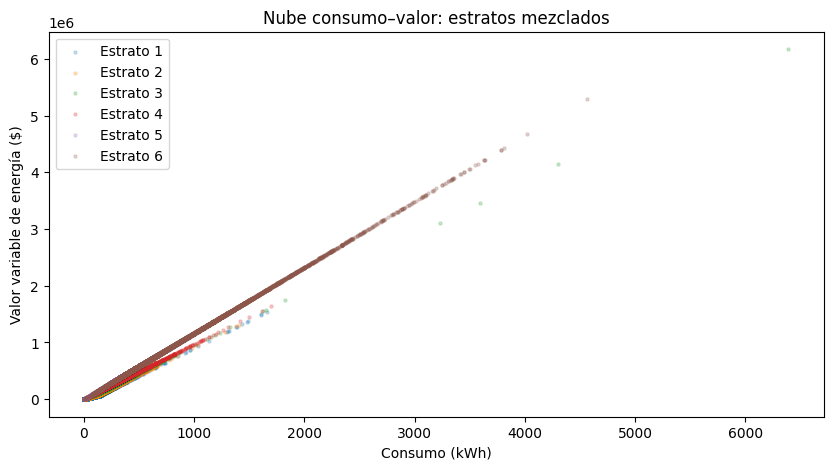

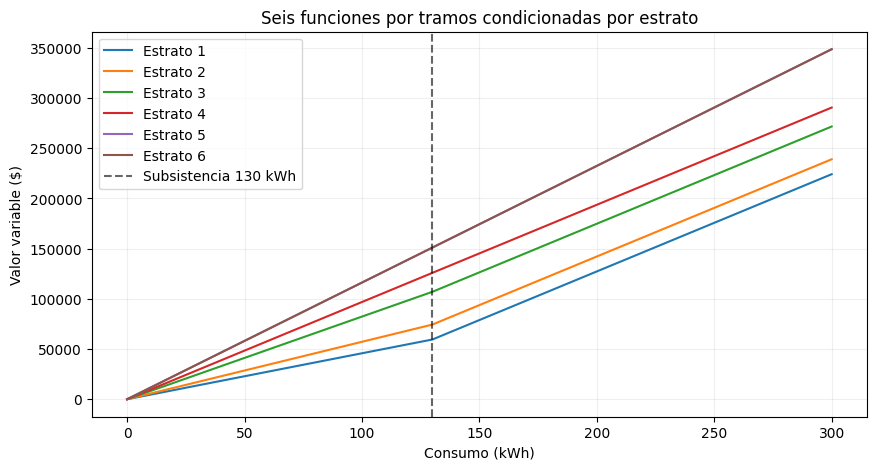

In [32]:
df_modelo["valor_pesos"] = [
    valor_factura(k, int(s)) for k,s in zip(df_modelo["kwh"], df_modelo["estrato"])
]
plt.figure(figsize=(10,5))
for s, grupo in df_modelo.groupby("estrato"):
    plt.scatter(grupo.kwh, grupo.valor_pesos, s=5, alpha=.22, label=f"Estrato {s}")
plt.xlabel("Consumo (kWh)")
plt.ylabel("Valor variable de energía ($)")
plt.title("Nube consumo–valor: estratos mezclados")
plt.legend()
plt.show()

# Curvas condicionadas por estrato
k_grid = np.linspace(0, 300, 301)
plt.figure(figsize=(10,5))
for s in range(1,7):
    plt.plot(k_grid, [valor_factura(k,s) for k in k_grid], label=f"Estrato {s}")
plt.axvline(130, linestyle="--", color="black", alpha=.6, label="Subsistencia 130 kWh")
plt.xlabel("Consumo (kWh)")
plt.ylabel("Valor variable ($)")
plt.title("Seis funciones por tramos condicionadas por estrato")
plt.legend()
plt.grid(alpha=.2)
plt.show()

## 10. Cuantificación estrato 3: 110→135 y 135→160 kWh

El consumo de subsistencia es 130 kWh/mes. El primer aumento de 25 kWh cruza el umbral: 20 kWh se cobran con tarifa subsidiada y 5 kWh con tarifa plena. El segundo aumento ocurre completamente por encima del umbral.

Con las tarifas oficiales de agosto de 2026 (estrato 3: $823,0378/kWh hasta 130 kWh y $968,2798/kWh por encima), los resultados son:
- 110 kWh: $90.534,16
- 135 kWh: $111.836,31
- 160 kWh: $136.043,31
- Incremento 110→135: **$21.302,16** (aprox. $21.302)
- Incremento 135→160: **$24.207,00** (aprox. $24.207)

El segundo incremento cuesta $2.904,84 más porque los 25 kWh adicionales se cobran todos a tarifa plena; en el primer incremento, 20 kWh aún estaban dentro del tramo subsidiado.

In [33]:
v110 = valor_factura(110, 3)
v135 = valor_factura(135, 3)
v160 = valor_factura(160, 3)
inc_110_135 = v135-v110
inc_135_160 = v160-v135
print(f"Factura variable a 110 kWh: ${v110:,.2f}")
print(f"Factura variable a 135 kWh: ${v135:,.2f}")
print(f"Factura variable a 160 kWh: ${v160:,.2f}")
print(f"Incremento 110→135: ${inc_110_135:,.2f} (≈ ${round(inc_110_135):,})")
print(f"Incremento 135→160: ${inc_135_160:,.2f} (≈ ${round(inc_135_160):,})")
print(f"Diferencia entre incrementos: ${inc_135_160-inc_110_135:,.2f}")

Factura variable a 110 kWh: $90,534.16
Factura variable a 135 kWh: $111,836.31
Factura variable a 160 kWh: $136,043.31
Incremento 110→135: $21,302.15 (≈ $21,302)
Incremento 135→160: $24,206.99 (≈ $24,207)
Diferencia entre incrementos: $2,904.84


## 11. Correlación

La correlación de Pearson resume la intensidad y dirección de una asociación lineal entre dos variables numéricas, entre −1 y 1. No demuestra causalidad, no detecta bien relaciones no lineales y puede cambiar al mezclar grupos distintos (por ejemplo, estratos).

In [34]:
variables_corr = df_modelo[["kwh","estrato"]].copy()
if "valor_pesos" in df_modelo.columns:
    variables_corr["valor_pesos"] = df_modelo["valor_pesos"]
display(variables_corr.corr(numeric_only=True))

,kwh,estrato,valor_pesos
kwh,1.000000,0.702284,0.995060
estrato,0.702284,1.000000,0.749737
valor_pesos,0.995060,0.749737,1.000000


## 12. Microdataset del curso

Fila anonimizada construida a partir del recibo adjunto. No se incluyen nombre, dirección, número de cuenta ni medidor.

In [35]:
microdataset = pd.DataFrame([{
    "codigo_anonimo": "HOGAR_01",
    "mes": "2026-09",
    "kwh": 184,
    "valor_pagado": 195000,
    "estrato": 4
}])
display(microdataset)
microdataset.to_csv("microdataset_equipo.csv", index=False)
print("Archivo microdataset_equipo.csv guardado.")

,codigo_anonimo,mes,kwh,valor_pagado,estrato
0,HOGAR_01,2026-09,184,195000,4


Archivo microdataset_equipo.csv guardado.


**Qué preguntas permite responder:** comparar consumo y valor pagado entre meses, y observar diferencias entre estratos. **Qué preguntas no permite responder:** causas del consumo, tamaño del hogar, número de habitantes o hábitos, porque esas variables no están en la tabla. Usar un código anónimo protege identidad y permite agrupar registros sin publicar datos personales.

## 13. Momento 3 — explicar (guía para redactar en equipo)

La guía exige una página con las dos discrepancias más interesantes entre predicción y resultado, defensa del criterio de estratificación y reflexión de tres líneas sobre qué fue real y qué fue supuesto. No se redacta como conclusión definitiva porque la guía prohíbe delegar esta parte a la IA.

**Hechos ya comprobables para usar:**
- La relación mes→consumo de toda la ciudad no es función; al fijar un hogar sí.
- El recibo real registra 184 kWh en 32 días y $195.000 de total.
- El componente de energía se reproduce con 184 × $968,2798 = $178.163,48, redondeado a $178.163.
- $16.837 corresponden a alumbrado público.
- Asignar estratos a Londres es un supuesto del modelo, no un dato observado.
- Aplicar tarifas CHEC a hogares londinenses es un escenario contrafactual.

## 14. Bitácora individual de IA

La guía exige que cada integrante registre su uso de IA. Plantilla:
1. Pregunta o prompt utilizado.
2. Respuesta recibida (resumen breve).
3. Qué acepté y cómo lo verifiqué.
4. Qué corregí o rechacé y por qué.
5. Veredicto de auditoría: ¿la IA inventó tarifas, cobró dos veces un tramo o ignoró el estrato?

## 15. Lista de entrega

- [ ] Exploración del CSV: dimensiones, hogares, rango de meses y `head()`.
- [ ] Dominios, ilegales y limpieza justificada.
- [ ] Histograma y mediana; curva mensual; comparación con predicciones.
- [ ] Test de recta vertical para ciudad y para un hogar.
- [ ] Tarea puente: `london_energy.csv`, agregación, comparación exacta y pantallazo.
- [ ] Defensa de cinco líneas de regla de 25 días y misterio de febrero.
- [ ] Consulta CHEC por API, inspección de dominios y campos.
- [ ] Función de facturación con tarifas oficiales y auditoría del recibo.
- [ ] Criterio de estratificación elegido y defendido por el equipo.
- [ ] Nube mezclada y seis curvas condicionadas por estrato.
- [ ] Diferencias de estrato 3 para 110→135 y 135→160 kWh.
- [ ] Matriz de correlación e interpretación.
- [ ] Microdataset con una fila por integrante.
- [ ] Momento 3 redactado por el equipo.
- [ ] Bitácora individual de IA.

**Advertencia:** el cuaderno no puede certificar tarifas de estratos 1, 2, 3, 5 y 6 ni las diferencias monetarias de estrato 3 hasta ejecutar y mapear correctamente la API CHEC. No se incluyen valores ficticios. La parte del recibo de estrato 4 sí queda auditada con datos reales.